In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Kalman filter and smoother with time-varying coefficients

In [2]:
def kalman_filter(Y, c, G, V, F, U, s0, P0):
    T, n = Y.shape
    m = F.shape[-1]

    s_pred = np.zeros((T, m))       # s_{t|t-1}
    P_pred = np.zeros((T, m, m))    # P_{t|t-1}
    s_filt = np.zeros((T, m))       # s_{t|t}
    P_filt = np.zeros((T, m, m))    # P_{t|t}
    y_pred = np.zeros((T, n))       # y_{t|t-1}
    Q_pred = np.zeros((T, n, n))    # Q_{t|t-1}

    s_prev, P_prev = s0, P0
    for t in range(T):
        # Predict
        s_pred[t] = F[t] @ s_prev
        P_pred[t] = F[t] @ P_prev @ F[t].T + U[t]
        y_pred[t] = c[t] + G[t] @ s_pred[t]
        Q_pred[t] = G[t] @ P_pred[t] @ G[t].T + V[t]

        # Gain
        K = np.linalg.solve(Q_pred[t], G[t] @ P_pred[t]).T

        # Update
        innov = Y[t] - y_pred[t]
        s_filt[t] = s_pred[t] + K @ innov
        P_filt[t] = P_pred[t] - K @ Q_pred[t] @ K.T

        s_prev, P_prev = s_filt[t], P_filt[t]

    return {'s_pred': s_pred, 'P_pred': P_pred,
            's_filt': s_filt, 'P_filt': P_filt,
            'y_pred': y_pred, 'Q_pred': Q_pred}

def kalman_smoother(filt, F):
    s_pred, P_pred = filt['s_pred'], filt['P_pred']
    s_filt, P_filt = filt['s_filt'], filt['P_filt']
    T, m = s_filt.shape

    s_smooth = np.zeros((T, m))     # s_{t|T}
    P_smooth = np.zeros((T, m, m))  # P_{t|T}

    # Initialize at final filtered state
    s_smooth[T - 1] = s_filt[T - 1]
    P_smooth[T - 1] = P_filt[T - 1]
    
    for t in range(T - 2, -1, -1):
        J = np.linalg.solve(P_pred[t + 1], F[t + 1] @ P_filt[t]).T
        s_smooth[t] = s_filt[t] + J @ (s_smooth[t + 1] - s_pred[t + 1])
        P_smooth[t] = P_filt[t] + J @ (P_smooth[t + 1] - P_pred[t + 1]) @ J.T

    return {'s_smooth': s_smooth, 'P_smooth': P_smooth}

## Time-varying parameter model

$y_t = \beta_t x_t + v_t, \quad \beta_t = \beta_{t-1} + u_t, \quad \begin{pmatrix}
v_t \\
u_t
\end{pmatrix} \overset{iid}{\sim} N\left(\begin{pmatrix}
0 \\
0
\end{pmatrix}, \begin{pmatrix}
\sigma_v^2 & 0 \\
0 & \sigma_u^2
\end{pmatrix}\right)$

In [3]:
# Simulate
T = 100
sigma_v = 0.5
sigma_u = 0.1
rho_x = 0.7
rng = np.random.default_rng(seed=31150)

# AR(1) covariate with variance=1
x = np.zeros(T)
x[0] = rng.standard_normal()
for t in range(1, T):
    x[t] = rho_x * x[t - 1] + np.sqrt(1 - rho_x**2) * rng.standard_normal()

# True beta path: random walk starting at 1
beta = np.zeros(T)
beta[0] = 1.0
for t in range(1, T):
    beta[t] = beta[t - 1] + sigma_u * rng.standard_normal()

y = beta * x + sigma_v * rng.standard_normal(T)

In [4]:
# Build time-varying state-space matrices
c = np.zeros((T, 1))
G = x.reshape(T, 1, 1)
V = np.full((T, 1, 1), sigma_v**2)
F = np.ones((T, 1, 1))
U = np.full((T, 1, 1), sigma_u**2)

# Diffuse initialization
s0 = np.zeros(1)
P0 = np.array([[100.0]])

# Run filter and smoother
filt = kalman_filter(y[:, None], c, G, V, F, U, s0, P0)
smooth = kalman_smoother(filt, F)

beta_smooth = smooth['s_smooth'][:, 0]
beta_smooth_se = np.sqrt(smooth['P_smooth'][:, 0, 0])

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


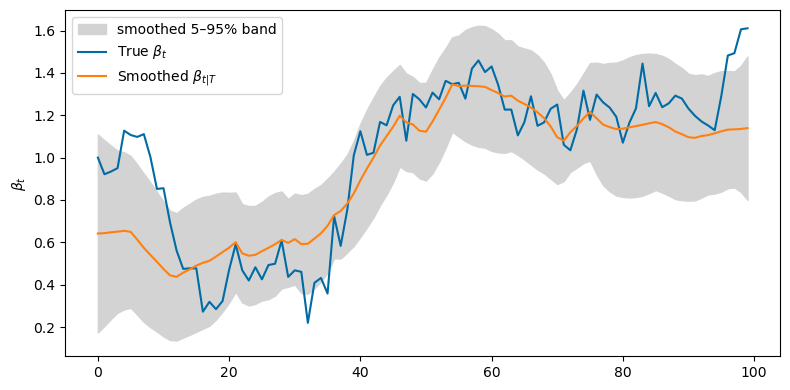

In [5]:
# Plot smoothed vs true beta path
cv = stats.norm.ppf(0.95)
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(np.arange(T),
                beta_smooth - cv * beta_smooth_se,
                beta_smooth + cv * beta_smooth_se,
                color='lightgrey', label='smoothed 5–95% band')
ax.plot(beta, label=r'True $\beta_t$')
ax.plot(beta_smooth, label=r'Smoothed $\beta_{t|T}$')
ax.set_ylabel(r'$\beta_t$')
ax.legend()
plt.tight_layout()
fig.savefig('output/tvp.eps')
plt.show()

## Factor model with missing data

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


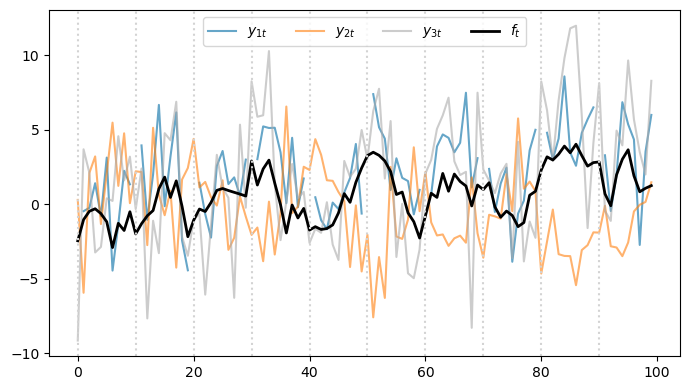

In [6]:
# DFM parameters
T = 100
a_1 = 0.8
lambdas = np.array([1.0, -1.0, 2.0])
sigmas2 = np.array([4.0, 4.0, 9.0])
c = np.array([1.0, 0.0, 0.0])

# Simulate
f_prev = rng.normal(0, 1/np.sqrt(1 - a_1**2))
f = np.zeros(T)
for t in range(T):
    f[t] = a_1 * f_prev + rng.normal()
    f_prev = f[t]
n = len(lambdas)
Y = c + lambdas * f[:, None] + rng.normal(scale=np.sqrt(sigmas2), size=(T, n))
miss_idx = np.arange(0, T, 10)
Y[miss_idx, 0] = np.nan  # every 10th obs of first series is missing

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(n):
    ax.plot(Y[:, i], alpha=0.6, label=f'$y_{{{i+1}t}}$')
ax.plot(f, 'k', linewidth=2, label='$f_t$')
for j, t_miss in enumerate(miss_idx):
    ax.axvline(t_miss, color='lightgray', linestyle=':')
ax.legend(ncol=4)
plt.tight_layout()
fig.savefig('output/factor_sim_missing.eps')
plt.show()

In [7]:
# State space matrices (on non-missing dates)
F = np.array([[a_1]])
U = np.array([[1.0]])
G = lambdas[:, None]
V = np.diag(sigmas2)

# Initial state from stationary distribution
s0 = np.zeros(1)
P0 = np.array([[1 / (1 - a_1**2)]])

c_t = np.broadcast_to(c, (T, n)).copy()
G_t = np.broadcast_to(G, (T, n, 1)).copy()
V_t = np.broadcast_to(V, (T, n, n)).copy()
F_t = np.broadcast_to(F, (T, 1, 1))
U_t = np.broadcast_to(U, (T, 1, 1))

# Zero out the first observation channel at missing dates
c_t[miss_idx, 0] = 0.0
G_t[miss_idx, 0, :] = 0.0
V_t[miss_idx, 0, :] = 0.0
V_t[miss_idx, :, 0] = 0.0
V_t[miss_idx, 0, 0] = 1 # arbitrary; cancels out of the filtered state

# Feed arbitrary value for the missing entries; the filter ignores them
Y_in = Y.copy()
Y_in[miss_idx, 0] = 0.0

# Run filter
filt = kalman_filter(Y_in, c_t, G_t, V_t, F_t, U_t, s0, P0)
f_filt = filt['s_filt'][:, 0]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


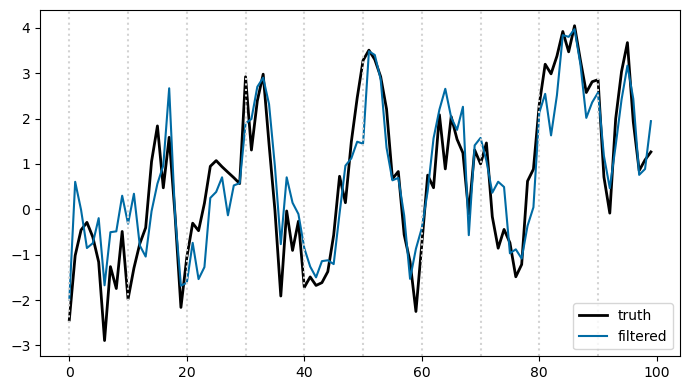

In [8]:
# Plot filtered factor against true factor
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f, 'k', linewidth=2, label='truth')
ax.plot(f_filt, label='filtered')
for t_miss in miss_idx:
    ax.axvline(t_miss, color='lightgray', linestyle=':')
ax.legend()
plt.tight_layout()
fig.savefig('output/factor_filter_missing.eps')
plt.show()

## Regime-switching AR(1)

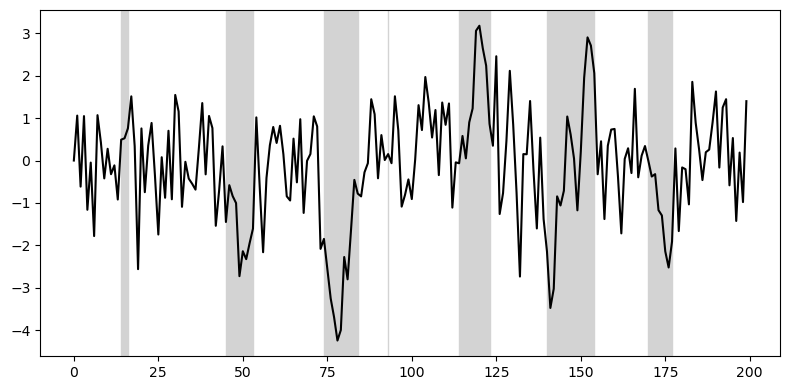

In [9]:
T = 200
rho_1 = 0.0 # regime 1: white noise
rho_2 = 0.9 # regime 2: persistent
p_switch = 0.1 # switching probability at each date

# Simulate Markov regime chain
s = np.zeros(T, dtype=int)
for t in range(1, T):
    s[t] = 1 - s[t-1] if rng.random() < p_switch else s[t-1]

# Simulate y_t
y = np.zeros(T)
for t in range(1, T):
    if s[t] == 0:
        y[t] = rho_1 * y[t-1] + rng.standard_normal()
    else:
        y[t] = rho_2 * y[t-1] + rng.standard_normal()

# Plot, shading regime-1 in light grey
fig, ax = plt.subplots(figsize=(8, 4))
edges = np.diff(s, prepend=0, append=0)
starts = np.where(edges == 1)[0]
ends = np.where(edges == -1)[0]
for t0, t1 in zip(starts, ends):
    ax.axvspan(t0, t1 - 1, color='lightgrey')
ax.plot(y, 'k')
plt.tight_layout()
fig.savefig('output/regime_switching.eps')
plt.show()